<div dir="rtl">

## بخش اول: شناخت داده‌ها و ساختار

### تسک ۱: منشأ داده و سازوکار جمع‌آوری
داده‌ها از پایگاه داده مرکز ملی هماهنگی آلزایمر آمریکا (NACC) گرفته شده است. این مرکز از سال ۲۰۰۵ اطلاعات شرکت‌کنندگان را از مراکز تحقیقاتی بیماری آلزایمر (ADRCs) در سراسر آمریکا جمع‌آوری می‌کند. 
زیرمجموعه‌ای که در این پروژه استفاده می‌کنیم شامل دو بخش اصلی است:
- **داده‌های بالینی و شناختی (UDS):** این اطلاعات در جریان ویزیت‌های سالانه شرکت‌کنندگان، از طریق معاینه مستقیم پزشک، مصاحبه با خود فرد یا همراه او، و گرفتن تست‌های استاندارد حافظه و شناخت روی فرم‌های مشخص ثبت شده است.
- **داده‌های تصویربرداری (MRI):** برای بخشی از این شرکت‌کنندگان اسکن مغزی انجام شده و اندازه‌گیری‌های عددی مربوط به حجم ماده خاکستری و ضخامت قشر نواحی مختلف مغز در این فایل قرار گرفته است.

از نظر آماری، این داده‌ها حاصل یک **مطالعه مشاهده‌ای** هستند؛ یعنی پژوهشگران هیچ مداخله یا آزمایشی روی افراد انجام نداده‌اند و صرفاً وضعیت سلامت، فشارخون، شاخص‌های بدنی و وضعیت مغزی آن‌ها را در مراجعات بالینی ثبت کرده‌اند. به همین خاطر، از این داده‌ها فقط می‌توان برای بررسی «ارتباط» بین متغیرها استفاده کرد و نمی‌توان نتیجه علت و معلولی قطعی گرفت.

در استفاده از این داده‌ها چند محدودیت مهم وجود دارد؛ اول اینکه دسترسی به پایگاه اصلی NACC عمومی نیست و در این پروژه هم ما به کل پایگاه داده دسترسی نداریم، بلکه فقط با یک زیرمجموعه از پیش تعیین‌شده کار می‌کنیم. دوم اینکه چون داده‌ها از مراکز تحقیقاتی مختلف جمع‌آوری شده‌اند، ممکن است دستگاه‌های تصویربرداری MRI یا نحوه تشخیص بالینی توسط پزشکان بین مراکز مختلف کمی متفاوت باشد.

</div>

<div dir="rtl">

### تسک ۲: واحد مشاهده و ساختار داده
در ساختار اصلی پایگاه داده NACC، اطلاعات بیماران به صورت طولی ثبت می‌شود؛ یعنی یک نفر ممکن است چندین بار به کلینیک مراجعه کرده باشد و چند ردیف داده داشته باشد. اما برای انجام تحلیل‌های آماری معتبر در این فاز، نیاز داریم که اصل استقلال مشاهدات رعایت شود.

با بررسی ابعاد داده‌ها در فایل‌های `udslong_imputed.csv` و `mriscanclean.csv` توسط پایتون، مشخص شد که داده‌هایی که برای این پروژه داریم فیلتر شده است. بنابراین، **واحد مشاهده** در داده‌های ما، دقیقاً نماینده **«یک شرکت‌کننده یکتا در یک مقطع زمانی مشخص»** است. 

همان‌طور که در خروجی کد زیر مشاهده می‌شود، هر دو فایل دارای ۱۲۳۷ سطر و ۱۲۳۷ شناسه یکتا (`NACCID`) هستند و هیچ رکورد تکراری برای بیماران در هیچ‌کدام از فایل‌ها وجود ندارد.

</div>

In [1]:
import pandas as pd

uds_df = pd.read_csv('../data/udslong_imputed.csv')
mri_df = pd.read_csv('../data/mriscanclean.csv')

print("--- بررسی مشاهدات در فایل بالینی (UDS) ---")
print(f"تعداد کل سطرها: {len(uds_df)}")
print(f"تعداد شناسه‌های یکتا (NACCID): {uds_df['NACCID'].nunique()}")

print("\n--- بررسی مشاهدات در فایل تصویربرداری (MRI) ---")
print(f"تعداد کل سطرها: {len(mri_df)}")
print(f"تعداد شناسه‌های یکتا (NACCID): {mri_df['NACCID'].nunique()}")

--- بررسی مشاهدات در فایل بالینی (UDS) ---
تعداد کل سطرها: 1237
تعداد شناسه‌های یکتا (NACCID): 1237

--- بررسی مشاهدات در فایل تصویربرداری (MRI) ---
تعداد کل سطرها: 1237
تعداد شناسه‌های یکتا (NACCID): 1237


<div dir="rtl">

### تسک ۳: نمونه‌گیری، انتخاب و قابلیت تعمیم

**سازوکار انتخاب و نمونه‌گیری:**
داده‌ها بر اساس نمونه‌گیری تصادفی از کل جامعه جمع‌آوری نشده‌اند. شرکت‌کنندگان شامل افرادی هستند که به مراکز تحقیقاتی بیماری آلزایمر (ADRCs) مراجعه کرده‌اند. این مراجعات معمولاً یا به صورت داوطلبانه (مثلاً به دلیل نگرانی فرد از وضعیت حافظه‌اش یا داشتن سابقه خانوادگی) و یا از طریق ارجاع توسط پزشکان متخصص صورت گرفته است. بنابراین، روش نمونه‌گیری از نوع **غیراحتمالی** است. 

**قابلیت تعمیم:**
از آنجا که نمونه‌گیری تصادفی نبوده و افراد از محیط‌های کلینیکی و تحقیقاتی انتخاب شده‌اند، **نمی‌توانیم نتایج پروژه را به کل جامعه سالمندان عادی تعمیم دهیم.** این نتایج صرفاً به جمعیتی با ویژگی‌های مشابه قابل تعمیم است؛ یعنی افرادی که به مراکز تحقیقاتی بیماری آلزایمر مراجعه می‌کنند و در مطالعات مرتبط با ارزیابی‌های شناختی و تصویربرداری مغز شرکت می‌کنند.

</div>

<div dir="rtl">

### تسک ۴: طبقه‌بندی متغیرها و مقیاس اندازه‌گیری

در جدول زیر، متغیرهایی که برای این پروژه انتخاب کرده‌ایم به همراه نوع آماری و نقش آن‌ها مشخص شده‌اند. برای بررسی ساختار لوب پیشانی در داده‌های MRI، تمرکز ما بر ناحیه **پیشانی فوقانی (Superior Frontal)** در هر دو نیمکره چپ و راست است که نقش کلیدی در عملکردهای شناختی و حافظه دارد.

| نام متغیر | منبع | توضیح متغیر | نوع آماری (مقیاس) | نقش در تحلیل |
| :--- | :--- | :--- | :--- | :--- |
| **`NACCID`** | هر دو فایل | شناسه یکتای بیمار | کیفی (اسمی) | کلید اتصال دو فایل |
| **`NACCBMI`** | بالینی | شاخص توده بدنی (BMI) | کمّی پیوسته (نسبی) | متغیر مستقل (ریسک‌فاکتور) |
| **`BPSYS`** | بالینی | فشار خون سیستولیک | کمّی پیوسته (نسبی) | متغیر مستقل (ریسک‌فاکتور) |
| **`HYPERTEN`** | بالینی | سابقه پرفشاری خون (کد ۰، ۱، ۲) | کیفی (اسمی) | متغیر مستقل (ریسک‌فاکتور) |
| **`MOCATOTS`** | بالینی | نمره تست شناختی MoCA (۰ تا ۳۰) | کمّی گسسته (نسبی) | متغیر وابسته (پیامد شناختی) |
| **`LH_SUPERIORFRONTAL_GVOL`** | MRI | حجم ماده خاکستری پیشانی فوقانی (چپ) | کمّی پیوسته (نسبی) | متغیر وابسته (ساختار مغز) |
| **`RH_SUPERIORFRONTAL_GVOL`** | MRI | حجم ماده خاکستری پیشانی فوقانی (راست) | کمّی پیوسته (نسبی) | متغیر وابسته (ساختار مغز) |
| **`LH_SUPERIORFRONTAL_AVGTH`** | MRI | ضخامت قشر پیشانی فوقانی (چپ) | کمّی پیوسته (نسبی) | متغیر وابسته (ساختار مغز) |
| **`RH_SUPERIORFRONTAL_AVGTH`** | MRI | ضخامت قشر پیشانی فوقانی (راست) | کمّی پیوسته (نسبی) | متغیر وابسته (ساختار مغز) |
| **`NACCAGE`** | بالینی | سن بیمار (سال) | کمّی پیوسته (نسبی) | متغیر کنترل (زمینه) |
| **`SEX`** | بالینی | جنسیت (۱=مرد، ۲=زن) | کیفی (اسمی) | متغیر کنترل (زمینه) |
| **`EDUC`** | بالینی | سنوات تحصیلات (سال) | کمّی گسسته (نسبی) | متغیر کنترل (زمینه) |

**نکته:** متغیرهای کیفی مانند جنسیت و سابقه فشار خون در فایل داده با عدد کدگذاری شده‌اند، اما ماهیت آماری آن‌ها دسته‌بندی است و در تحلیل‌های بعدی به همین صورت با آن‌ها رفتار خواهد شد.

</div>

In [2]:
selected_uds = ['NACCID', 'NACCAGE', 'SEX', 'EDUC', 'NACCBMI', 'BPSYS', 'HYPERTEN', 'MOCATOTS']
selected_mri = ['NACCID', 'LH_SUPERIORFRONTAL_GVOL', 'RH_SUPERIORFRONTAL_GVOL', 
                'LH_SUPERIORFRONTAL_AVGTH', 'RH_SUPERIORFRONTAL_AVGTH']

print("--- تعداد مقادیر گمشده در داده‌های بالینی (UDS) ---")
print(uds_df[selected_uds].isna().sum())

print("\n--- تعداد مقادیر گمشده در داده‌های تصویربرداری (MRI) ---")
print(mri_df[selected_mri].isna().sum())

print("\n--- خلاصه وضعیت داده‌های بالینی ---")
display(uds_df[selected_uds].describe().round(2))

print("\n--- خلاصه وضعیت داده‌های تصویربرداری ---")
display(mri_df[selected_mri].describe().round(2))

--- تعداد مقادیر گمشده در داده‌های بالینی (UDS) ---
NACCID      0
NACCAGE     0
SEX         0
EDUC        0
NACCBMI     0
BPSYS       0
HYPERTEN    0
MOCATOTS    0
dtype: int64

--- تعداد مقادیر گمشده در داده‌های تصویربرداری (MRI) ---
NACCID                      0
LH_SUPERIORFRONTAL_GVOL     0
RH_SUPERIORFRONTAL_GVOL     0
LH_SUPERIORFRONTAL_AVGTH    0
RH_SUPERIORFRONTAL_AVGTH    0
dtype: int64

--- خلاصه وضعیت داده‌های بالینی ---


,NACCAGE,SEX,EDUC,NACCBMI,BPSYS,HYPERTEN,MOCATOTS
count,1237.00,1237.00,1237.00,1237.00,1237.00,1237.00,1237.00
mean,68.19,1.60,16.39,117.03,214.11,0.50,24.65
std,8.04,0.49,4.29,261.98,221.36,0.97,5.75
min,41.00,1.00,0.00,15.60,83.00,0.00,0.00
25%,63.00,1.00,14.00,24.10,122.00,0.00,23.00
50%,68.00,2.00,16.00,27.30,135.00,0.00,25.40
75%,74.00,2.00,18.00,32.20,152.00,1.00,27.00
max,91.00,2.00,99.00,888.80,888.00,9.00,88.00



--- خلاصه وضعیت داده‌های تصویربرداری ---


,LH_SUPERIORFRONTAL_GVOL,RH_SUPERIORFRONTAL_GVOL,LH_SUPERIORFRONTAL_AVGTH,RH_SUPERIORFRONTAL_AVGTH
count,1237.00,1237.00,1237.00,1237.00
mean,21764.81,23988.37,2.49,2.47
std,3145.38,3635.76,0.15,0.14
min,2035.00,2354.00,1.03,1.12
25%,19963.00,21846.00,2.42,2.40
50%,21706.00,23822.00,2.50,2.48
75%,23571.00,26158.00,2.58,2.56
max,31261.00,43087.00,2.90,2.91


<div dir="rtl">

**نتیجه‌گیری بررسی کیفیت داده‌ها:**
همان‌طور که در خروجی‌های بالا مشاهده می‌شود، هیچ مقدار گمشده استانداردی (`NaN`) در داده‌ها وجود ندارد. با این حال، بررسی جدول آمار توصیفی در داده‌های بالینی (UDS) نشان می‌دهد که از یک‌سری کدهای قراردادی عددی (اعداد بسیار بزرگ یا خارج از محدوده منطقی) به جای مقادیر گمشده استفاده شده است. این اعداد در واقع کدهای تعریف‌شده توسط NACC برای داده‌های «نامشخص»، «اخذنشده» یا «امتناع از پاسخ» هستند. از سوی دیگر، داده‌های تصویربرداری (MRI) تمیز بوده و فاقد مقادیر پرت یا کدهای نامعتبر هستند.

</div>

<div dir="rtl">

### تسک ۶: پاکسازی داده‌ها و ادغام نهایی 

در این مرحله، ابتدا کدهای قراردادیِ مربوط به داده‌های گمشده (مانند ۸۸۸ یا ۹۹) را بر اساس دفترچه راهنمای NACC با مقدار استاندارد `NaN` جایگزین می‌کنیم. 
سپس تعداد این مقادیر گمشده را بررسی می‌کنیم تا برای نحوه برخورد با آن‌ها تصمیم بگیریم. از آنجا که درصد داده‌های ناقص نسبت به کل حجم نمونه پایین است، نیازی به استفاده از روش‌های جایگذاری مصنوعی نیست. بنابراین پس از ادغام دو فایل بالینی و تصویربرداری، از رویکرد **تحلیل موارد کامل (Complete Case Analysis)** استفاده کرده و بیماران دارای اطلاعات ناقص را حذف می‌کنیم تا تحلیل‌های آماری روی داده‌های ۱۰۰ درصد واقعی و معتبر انجام شود.

</div>

In [3]:
import numpy as np
import pandas as pd

selected_uds = ['NACCID', 'NACCAGE', 'SEX', 'EDUC', 'NACCBMI', 'BPSYS', 'HYPERTEN', 'MOCATOTS']
selected_mri = ['NACCID', 'LH_SUPERIORFRONTAL_GVOL', 'RH_SUPERIORFRONTAL_GVOL', 
                'LH_SUPERIORFRONTAL_AVGTH', 'RH_SUPERIORFRONTAL_AVGTH']

df_clinical = uds_df[selected_uds].copy()
df_mri = mri_df[selected_mri].copy()

missing_codes = {
    'NACCBMI': [888.8, -4],
    'BPSYS': [888, 777, -4],
    'MOCATOTS': [88, -4],
    'EDUC': [99],
    'HYPERTEN': [9, -4]
}

for col, codes in missing_codes.items():
    df_clinical[col] = df_clinical[col].replace(codes, np.nan)

print("--- تعداد مقادیر گمشده (NaN) در هر متغیر ---")
print(df_clinical.isna().sum())
print("\n" + "="*45 + "\n")

df_merged = pd.merge(df_clinical, df_mri, on='NACCID', how='inner')
df_final = df_merged.dropna()

print(f"تعداد کل بیماران قبل از پاکسازی: {len(df_merged)}")
print(f"تعداد بیماران دارای داده‌های کامل و آماده تحلیل: {len(df_final)}")

--- تعداد مقادیر گمشده (NaN) در هر متغیر ---
NACCID        0
NACCAGE       0
SEX           0
EDUC          2
NACCBMI     126
BPSYS       106
HYPERTEN     11
MOCATOTS      4
dtype: int64


تعداد کل بیماران قبل از پاکسازی: 1237
تعداد بیماران دارای داده‌های کامل و آماده تحلیل: 1050


<div dir="rtl">

### پچ اصلاحی داده‌ها (Data Quality Patch)
در بررسی‌های اولیه پیش از محاسبه آمار توصیفی، متوجه دو خطای پنهان در داده‌های خام شدیم که نیازمند اصلاح فوری هستند:
۱. **اعداد اعشاری در سابقه فشار خون :** به دلیل استفاده سازندگان دیتاست از روش‌های جایگذاری ، این متغیرِ دسته‌ای دارای مقادیر اعشاری شده است. این مقادیر باید به کدهای استاندارد پزشکی (۰، ۱ و ۲) گِرد شوند.
۲. **مقادیر غیرممکن در شاخص توده بدنی :** مقادیری مانند `719` در داده‌ها یافت شد که فراتر از محدوده مجاز پزشکی (حداکثر `100` طبق راهنمای NACC) است و احتمالا ناشی از خطای تایپی اپراتورهاست. 
در این مرحله، این دو مشکل را برطرف کرده و ردیف‌های نامعتبر را با یک فیلتر منطقی حذف می‌کنیم.

</div>

In [4]:
import numpy as np

print("=== شروع عملیات اصلاح داده‌ها ===")
initial_count = len(df_final)
print(f"تعداد بیماران قبل از اصلاح: {initial_count}")

df_final.loc[:, 'HYPERTEN'] = df_final['HYPERTEN'].round()

df_final.loc[df_final['NACCBMI'] > 100, 'NACCBMI'] = np.nan
df_final = df_final.dropna()

final_count = len(df_final)
removed_count = initial_count - final_count

print("\n=== گزارش نهایی ===")
print(f"تعداد بیماران حذف شده در این فیلتر: {removed_count}")
print(f"تعداد نهایی بیماران تر و تمیز: {final_count}")
print(f"بیشترین مقدار BMI معتبر پس از اصلاح: {df_final['NACCBMI'].max()}")
print(f"کدهای موجود در ستون HYPERTEN: {df_final['HYPERTEN'].unique()}")

=== شروع عملیات اصلاح داده‌ها ===
تعداد بیماران قبل از اصلاح: 1050

=== گزارش نهایی ===
تعداد بیماران حذف شده در این فیلتر: 4
تعداد نهایی بیماران تر و تمیز: 1046
بیشترین مقدار BMI معتبر پس از اصلاح: 52.4
کدهای موجود در ستون HYPERTEN: [1. 0. 2.]


In [5]:
import pandas as pd

quant_vars = ['NACCAGE', 'EDUC', 'NACCBMI', 'BPSYS', 'MOCATOTS', 
              'LH_SUPERIORFRONTAL_GVOL', 'RH_SUPERIORFRONTAL_GVOL',
              'LH_SUPERIORFRONTAL_AVGTH', 'RH_SUPERIORFRONTAL_AVGTH']

desc_stats = df_final[quant_vars].describe().T

desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']
desc_stats['Skewness'] = df_final[quant_vars].skew()

final_stats = desc_stats[['mean', '50%', 'std', '25%', '75%', 'IQR', 'Skewness']]
final_stats.columns = ['Mean', 'Median', 'Std Dev', 'Q1 (25%)', 'Q3 (75%)', 'IQR', 'Skewness']

print("=== Descriptive Statistics for Quantitative Variables ===")
display(final_stats.round(2))

print("\n=== Frequency Tables for Categorical Variables ===")

for cat_var in ['HYPERTEN', 'SEX']:
    print(f"\n--- {cat_var} ---")
    freq = df_final[cat_var].value_counts()
    pct = df_final[cat_var].value_counts(normalize=True) * 100
    table = pd.DataFrame({'Count': freq, 'Percentage (%)': pct}).round(2)
    display(table)

=== Descriptive Statistics for Quantitative Variables ===


,Mean,Median,Std Dev,Q1 (25%),Q3 (75%),IQR,Skewness
NACCAGE,68.39,69.00,7.84,64.00,74.00,10.00,-0.26
EDUC,16.20,16.00,2.76,14.00,18.00,4.00,-0.97
NACCBMI,27.43,26.50,5.15,23.72,30.28,6.55,0.90
BPSYS,133.84,132.00,20.66,120.00,144.00,24.00,3.44
MOCATOTS,24.52,25.60,4.36,23.00,27.00,4.00,-1.66
LH_SUPERIORFRONTAL_GVOL,21690.23,21622.50,3108.96,19923.00,23476.25,3553.25,-1.07
RH_SUPERIORFRONTAL_GVOL,23864.32,23730.50,3581.51,21761.50,26033.00,4271.50,-0.83
LH_SUPERIORFRONTAL_AVGTH,2.49,2.50,0.14,2.42,2.58,0.16,-2.56
RH_SUPERIORFRONTAL_AVGTH,2.47,2.48,0.14,2.40,2.55,0.15,-2.34



=== Frequency Tables for Categorical Variables ===

--- HYPERTEN ---


,Count,Percentage (%)
HYPERTEN,,
0.0,611,58.41
1.0,405,38.72
2.0,30,2.87



--- SEX ---


,Count,Percentage (%)
SEX,,
2.0,620,59.27
1.0,426,40.73


Matplotlib is building the font cache; this may take a moment.
C:\Users\M.H.D Specialty Co\AppData\Local\Temp\ipykernel_1516\1900836793.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_final, x='HYPERTEN', ax=axes[0, 0], palette='Set2')
C:\Users\M.H.D Specialty Co\AppData\Local\Temp\ipykernel_1516\1900836793.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_final, x='SEX', ax=axes[0, 1], palette='pastel')


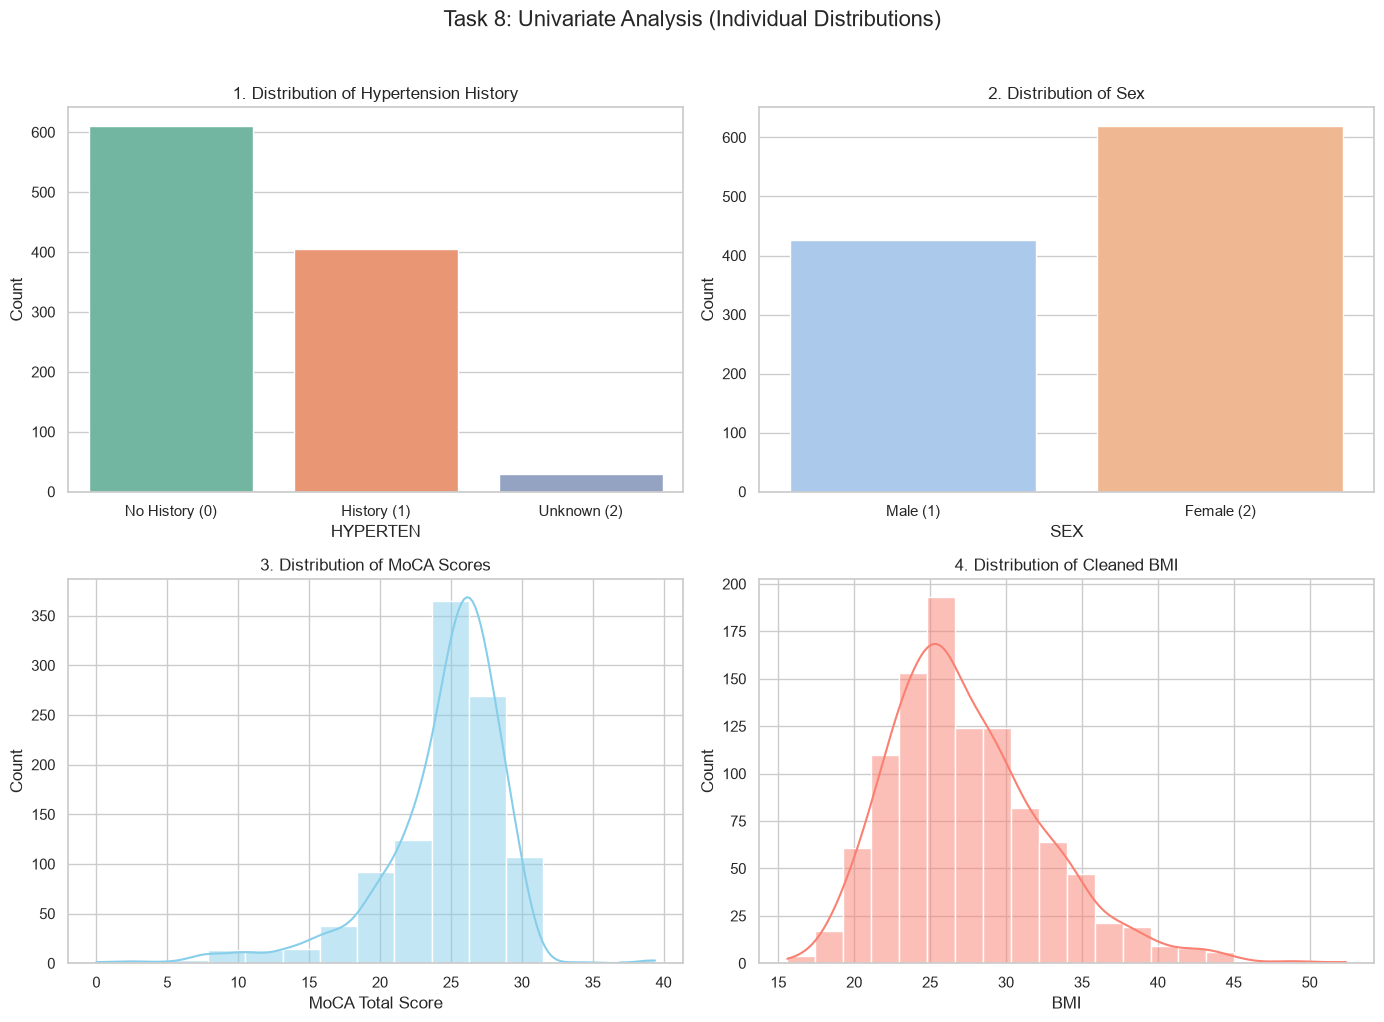

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Task 8: Univariate Analysis (Individual Distributions)', fontsize=16, y=1.02)

sns.countplot(data=df_final, x='HYPERTEN', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('1. Distribution of Hypertension History')
axes[0, 0].set_xticks([0, 1, 2])
axes[0, 0].set_xticklabels(['No History (0)', 'History (1)', 'Unknown (2)'])
axes[0, 0].set_ylabel('Count')

sns.countplot(data=df_final, x='SEX', ax=axes[0, 1], palette='pastel')
axes[0, 1].set_title('2. Distribution of Sex')
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_xticklabels(['Male (1)', 'Female (2)'])
axes[0, 1].set_ylabel('Count')

sns.histplot(data=df_final, x='MOCATOTS', bins=15, kde=True, ax=axes[1, 0], color='skyblue')
axes[1, 0].set_title('3. Distribution of MoCA Scores')
axes[1, 0].set_xlabel('MoCA Total Score')

sns.histplot(data=df_final, x='NACCBMI', bins=20, kde=True, ax=axes[1, 1], color='salmon')
axes[1, 1].set_title('4. Distribution of Cleaned BMI')
axes[1, 1].set_xlabel('BMI')

plt.tight_layout()
plt.show()